### Create graph from edges

In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import pandas as pd

df = pd.read_csv("../../../../0_DATA/HAHN/03a_all_edges_all_ffs.csv")

# Remove rows with NaNs in specific columns
df = df.dropna(subset=["DDG_OpenFF-1.0","DDG_OpenFF-2.0","DDG_OPLS3e", "DDG_GAFF2", "DDG_cGenFF", "DDG_Consensus_OpenFF_GAFF2_cGenFF"])
df.columns

Index(['Unnamed: 0', 'target', 'edge', 'ligandA', 'ligandB', 'unit',
       'DDG_Exp.', 'dDDG_Exp.', 'DDG_OpenFF-1.0', 'dDDG_OpenFF-1.0',
       'DDG_OpenFF-1.0_converged', 'dDDG_OpenFF-1.0_converged',
       'DDG_OpenFF-1.2', 'dDDG_OpenFF-1.2', 'DDG_OpenFF-1.2_converged',
       'dDDG_OpenFF-1.2_converged', 'DDG_OpenFF-2.0', 'dDDG_OpenFF-2.0',
       'DDG_OpenFF-2.0_converged', 'dDDG_OpenFF-2.0_converged', 'DDG_OPLS3e',
       'dDDG_OPLS3e', 'DDG_GAFF2', 'dDDG_GAFF2', 'DDG_cGenFF', 'dDDG_cGenFF',
       'DDG_Consensus_OpenFF_GAFF2_cGenFF',
       'dDDG_Consensus_OpenFF_GAFF2_cGenFF', 'DDG_Consensus_OpenFF_GAFF2',
       'dDDG_Consensus_OpenFF_GAFF2', 'DDG_Consensus_all',
       'dDDG_Consensus_all', 'error_OpenFF-1.0', 'abserror_OpenFF-1.0',
       'error_OpenFF-1.0_converged', 'abserror_OpenFF-1.0_converged',
       'error_OpenFF-1.2', 'abserror_OpenFF-1.2', 'error_OpenFF-1.2_converged',
       'abserror_OpenFF-1.2_converged', 'error_OpenFF-2.0',
       'abserror_OpenFF-2.0', 'error_

In [2]:
import networkx as nx

graphs = {}

# Group by 'target' and build one DiGraph per group
for target, group in df.groupby('target'):
    G = nx.DiGraph()
    for _, row in group.iterrows():
        node1 = row['ligandA']
        node2 = row['ligandB']
        weight = row['DDG_OpenFF-2.0']
        G.add_edge(node1, node2, weight=weight)
    graphs[target] = G  # store a graph per target


### Calculate ddG values from graph

In [3]:
# Make sure all graphs are fully connected
for target, G in graphs.items():
    if nx.is_connected(G.to_undirected()):
        continue
    else:
        raise NameError("not fuly conected graph")

In [4]:
total_expected_paths = 0

for target, G in graphs.items():
    n = len(G.nodes)
    expected = n * (n - 1)
    total_expected_paths += expected
    #print(f"{target}: {expected} directed paths")
    #print(n_nodes)

print(f"\ntotal expected paths across all targets: {total_expected_paths}")


total expected paths across all targets: 17988


In [5]:
from itertools import permutations

def signed_path_weight(G, path, weight='weight'):
    total = 0
    for u, v in zip(path, path[1:]):
        if G.has_edge(u, v):
            total += G[u][v][weight]
        else:
            total -= G[v][u][weight]
    return total

results = []
same_length_path_counts = []

# Create undirected graph to obtain all shortest paths (In a directed graph paths could not be found involving a backwards edge)
for target, G in graphs.items():
    UG = G.to_undirected()
    ligands = list(UG.nodes)

    # Get all possible shortest paths
    for source, target_node in permutations(ligands, 2):
        if nx.has_path(UG, source, target_node):
            all_paths = list(nx.all_shortest_paths(UG, source, target_node))
            n_paths = len(all_paths)
            same_length_path_counts.append(n_paths) 

            # Iterate through these shortest paths and store data
            for path in all_paths:
                ddG = signed_path_weight(G, path)
                results.append({
                    'target': target,
                    'ligandA': source,
                    'ligandB': target_node,
                    'path': path,
                    'n_steps': len(path) - 1,
                    'sum_ddG': ddG,
                    'n_paths': n_paths
                })
        else:
            raise NameError(f"no path between {source} and {target_node} in {target}")


df_G = pd.DataFrame(results)

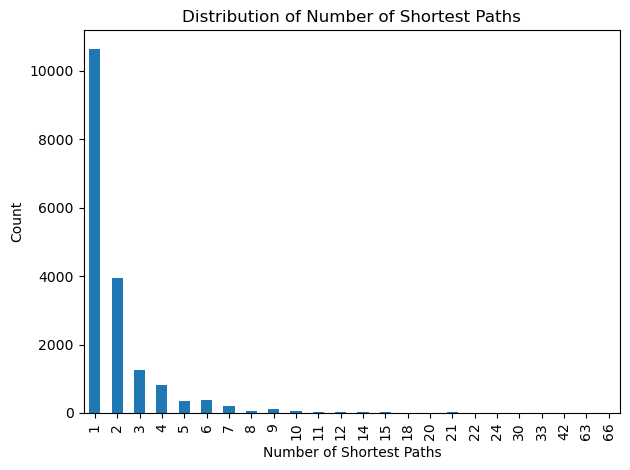

In [6]:
import matplotlib.pyplot as plt

plt.figure()
pd.Series(same_length_path_counts).value_counts().sort_index().plot(kind='bar')
plt.xlabel('Number of Shortest Paths')
plt.ylabel('Count')
plt.title('Distribution of Number of Shortest Paths')
plt.tight_layout()
plt.show()

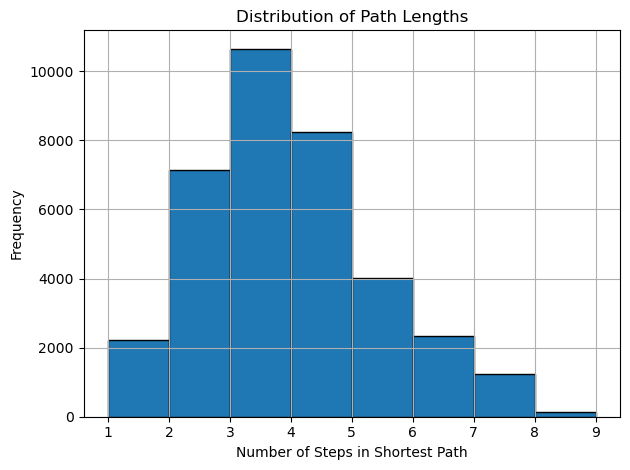

In [7]:
### Show n steps
import matplotlib.pyplot as plt

plt.figure()
df_G['n_steps'].hist(bins=range(1, df_G['n_steps'].max() + 2), edgecolor='black')
plt.xlabel('Number of Steps in Shortest Path')
plt.ylabel('Frequency')
plt.title('Distribution of Path Lengths')
plt.tight_layout()
plt.show()


### Compare to ddG values obtained ML (Maximum Likelihood/Arsenic)

In [8]:
# Add 'pair' column to df_G (df_paths) with formatted ligand pair key
df_G['pair'] = df_G.apply(
    lambda row: f"lig_{row['ligandA']}__lig_{row['ligandB']}", axis=1
)
df_G

,target,ligandA,ligandB,path,n_steps,sum_ddG,n_paths,pair
0,bace,CAT-13a,CAT-13m,"[CAT-13a, CAT-13m]",1,-1.696667,1,lig_CAT-13a__lig_CAT-13m
1,bace,CAT-13a,CAT-17g,"[CAT-13a, CAT-17g]",1,-1.263333,1,lig_CAT-13a__lig_CAT-17g
2,bace,CAT-13a,CAT-17i,"[CAT-13a, CAT-17i]",1,-1.863333,1,lig_CAT-13a__lig_CAT-17i
3,bace,CAT-13a,CAT-13b,"[CAT-13a, CAT-17g, CAT-13b]",2,-0.243333,1,lig_CAT-13a__lig_CAT-13b
4,bace,CAT-13a,CAT-13c,"[CAT-13a, CAT-17g, CAT-13c]",2,-1.503333,2,lig_CAT-13a__lig_CAT-13c
...,...,...,...,...,...,...,...,...
35973,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_28, ejm_31, ejm_49, ejm_50]",4,1.783333,2,lig_jmc_30__lig_ejm_50
35974,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_23, ejm_55, ejm_42, ejm_50]",4,1.553333,2,lig_jmc_30__lig_ejm_50
35975,tyk2,jmc_30,jmc_23,"[jmc_30, jmc_23]",1,0.293333,1,lig_jmc_30__lig_jmc_23
35976,tyk2,jmc_30,jmc_27,"[jmc_30, jmc_28, jmc_27]",2,0.430000,2,lig_jmc_30__lig_jmc_27


In [9]:
# Sanity check
df_G[df_G["n_paths"]> 1]

,target,ligandA,ligandB,path,n_steps,sum_ddG,n_paths,pair
4,bace,CAT-13a,CAT-13c,"[CAT-13a, CAT-17g, CAT-13c]",2,-1.503333,2,lig_CAT-13a__lig_CAT-13c
5,bace,CAT-13a,CAT-13c,"[CAT-13a, CAT-17i, CAT-13c]",2,0.280000,2,lig_CAT-13a__lig_CAT-13c
6,bace,CAT-13a,CAT-13d,"[CAT-13a, CAT-17g, CAT-13i, CAT-13d]",3,-3.346667,6,lig_CAT-13a__lig_CAT-13d
7,bace,CAT-13a,CAT-13d,"[CAT-13a, CAT-17g, CAT-17d, CAT-13d]",3,-2.543333,6,lig_CAT-13a__lig_CAT-13d
8,bace,CAT-13a,CAT-13d,"[CAT-13a, CAT-17g, CAT-13b, CAT-13d]",3,-2.363333,6,lig_CAT-13a__lig_CAT-13d
...,...,...,...,...,...,...,...,...
35971,tyk2,jmc_30,ejm_47,"[jmc_30, jmc_23, ejm_55, ejm_47]",3,0.440000,2,lig_jmc_30__lig_ejm_47
35973,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_28, ejm_31, ejm_49, ejm_50]",4,1.783333,2,lig_jmc_30__lig_ejm_50
35974,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_23, ejm_55, ejm_42, ejm_50]",4,1.553333,2,lig_jmc_30__lig_ejm_50
35976,tyk2,jmc_30,jmc_27,"[jmc_30, jmc_28, jmc_27]",2,0.430000,2,lig_jmc_30__lig_jmc_27


In [10]:
# group by pair & target, compute avg and range of sum_ddG
df_G['avg_sum_ddG'] = df_G.groupby(['pair', 'target'])['sum_ddG'].transform('mean')
df_G['ddG_range']  = df_G.groupby(['pair', 'target'])['sum_ddG'].transform(lambda x: x.max() - x.min())

# filter rows where n_paths > 1
df_G_filtered = df_G[df_G['n_paths'] > 1]

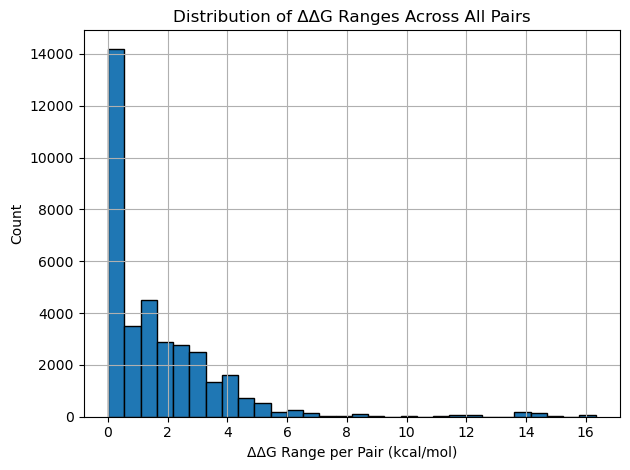

In [11]:
# Plot the ddG ranges
import matplotlib.pyplot as plt

plt.figure()
df_G['ddG_range'].hist(bins=30, edgecolor='black')
plt.xlabel('ΔΔG Range per Pair (kcal/mol)')
plt.ylabel('Count')
plt.title('Distribution of ΔΔG Ranges Across All Pairs')
plt.tight_layout()
plt.show()


In [12]:
# Look at outliers wrt ddG_range
outliers = df_G[df_G["ddG_range"]> 5]
print(len(df_G))
print(len(outliers))
print(len(outliers)/len(df_G)) 
outliers.head(30)

35978
1812
0.050364111401411976


,target,ligandA,ligandB,path,n_steps,sum_ddG,n_paths,pair,avg_sum_ddG,ddG_range
5542,cdk8,13,29,"[13, 42, 24, 33, 29]",4,3.536667,2,lig_13__lig_29,0.621667,5.83
5543,cdk8,13,29,"[13, 42, 43, 38, 29]",4,-2.293333,2,lig_13__lig_29,0.621667,5.83
5939,cdk8,45,33,"[45, 43, 38, 29, 33]",4,-1.293333,2,lig_45__lig_33,1.621667,5.83
5940,cdk8,45,33,"[45, 43, 42, 24, 33]",4,4.536667,2,lig_45__lig_33,1.621667,5.83
6035,cdk8,32,43,"[32, 33, 29, 38, 43]",4,-0.070000,2,lig_32__lig_43,-2.985000,5.83
6036,cdk8,32,43,"[32, 33, 24, 42, 43]",4,-5.900000,2,lig_32__lig_43,-2.985000,5.83
6110,cdk8,21,42,"[21, 29, 33, 24, 42]",4,-6.366667,2,lig_21__lig_42,-3.451667,5.83
6111,cdk8,21,42,"[21, 29, 38, 43, 42]",4,-0.536667,2,lig_21__lig_42,-3.451667,5.83
6152,cdk8,26,42,"[26, 21, 29, 33, 24, 42]",5,-6.023333,3,lig_26__lig_42,-4.180000,6.13
6153,cdk8,26,42,"[26, 22, 32, 33, 24, 42]",5,-6.323333,3,lig_26__lig_42,-4.180000,6.13


### Hahn: Is the error maybe due to bad edges (ddG calculations)? -> Compare ddG_GRAPGH (FEP) to  ddG experimental

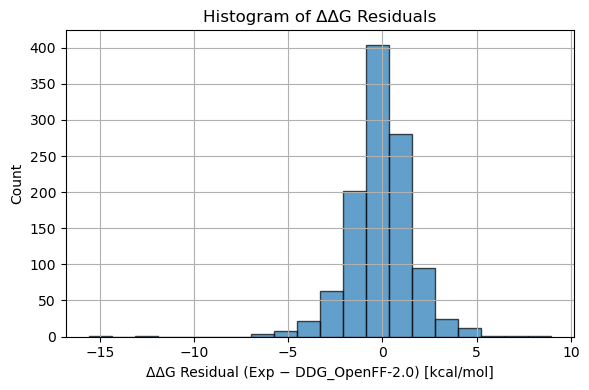

In [13]:
import matplotlib.pyplot as plt

# === Parameters ===
alpha = 0.7
bins = 20

# === Compute residuals ===
df['Residual'] = df['DDG_Exp.'] - df['DDG_OpenFF-2.0']

# === Plot histogram ===
plt.figure(figsize=(6, 4))
plt.hist(df['Residual'], bins=bins, alpha=alpha, edgecolor='black')

plt.xlabel('ΔΔG Residual (Exp − DDG_OpenFF-2.0) [kcal/mol]')
plt.ylabel('Count')
plt.title('Histogram of ΔΔG Residuals')
plt.grid(True)
plt.tight_layout()
plt.show()


### Save ddG Values

In [14]:
data_for_df = []

for _, row in df_G.iterrows():
    ligandA = row['ligandA']  # extract ligandA from current row
    ligandB = row['ligandB']  # extract ligandB from current row
    target = row['target']    # extract target from current row
    avg_sum_ddG = row['avg_sum_ddG']  # extract avg_sum_ddG from current row

    name = f"lig_{ligandA}__lig_{ligandB}"  # prepend "lig" to names
    data_for_df.append({'target': target, 'pair': name, 'DDG': avg_sum_ddG})
    
res_df_G = pd.DataFrame(data_for_df)
res_df_G.to_csv('OPENFF_FEP_DDG_FROM_GRAPH.csv', index=False)